# 099｜高效注意力与长上下文

CPU离线实验。先读lecture.md和lab.md，从本讲目录按序运行；重跑覆盖本目录outputs。

In [1]:
from pathlib import Path
import json, numpy as np
import experiment as e
print("Ready: CPU experiment")

Ready: CPU experiment


## 运行完整协议

不跳过失败配置，不将墙钟时间视为固定硬件保证。

In [2]:
e.main()

{
  "protocol": "CPU float64, one thread, warmup 1, 9 timed forward passes; alternating method order; block size 32. Bidirectional attention correctness. Synthetic single-query retrieval is not a trained language-model benchmark.",
  "max_abs_error": 5.551115123125783e-16,
  "full_successes": 12,
  "local_successes": 5,
  "retrieval_count": 12,
  "memory_scope": "Score tile size is an analytical buffer lower-level accounting, not measured peak memory; GPU memory not available."
}


In [3]:
metrics = json.loads(Path("outputs/metrics.json").read_text())
print("Result fields:", list(metrics))

Result fields: ['protocol', 'max_abs_error', 'timings', 'retrieval', 'full_successes', 'local_successes', 'retrieval_count', 'memory_scope']


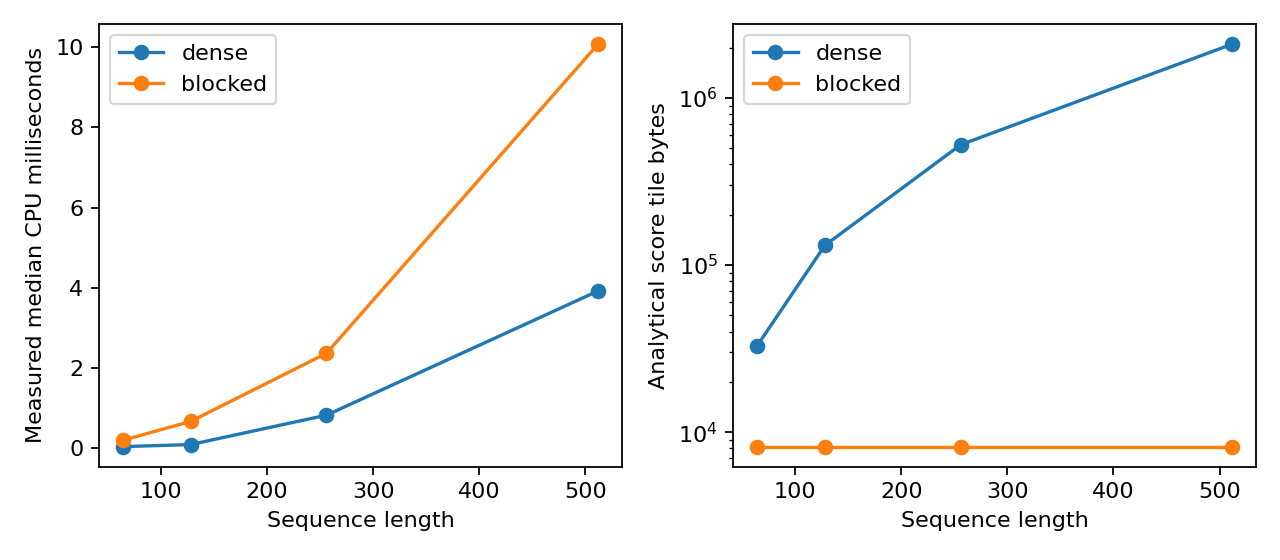

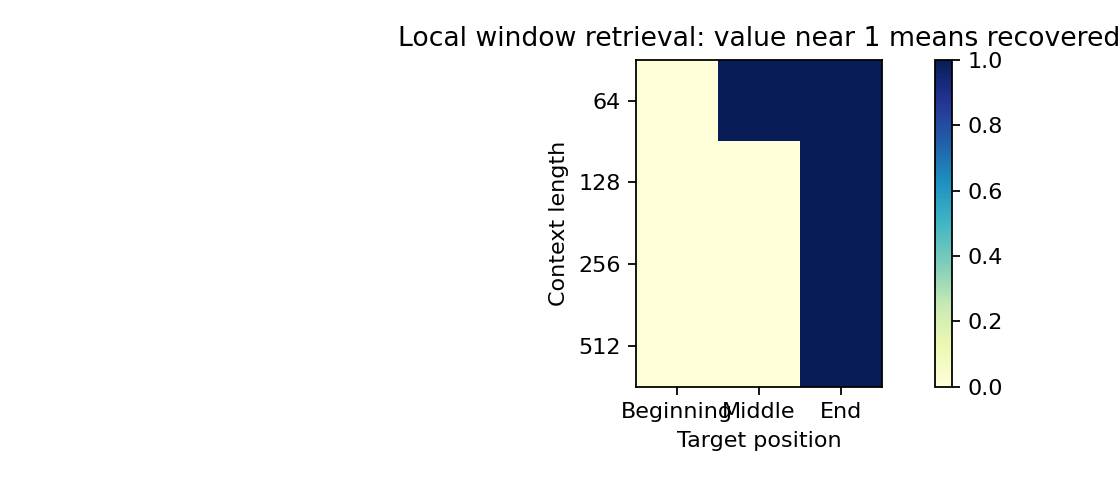

In [4]:
from IPython.display import display, Image
for path in sorted(Path("figures").glob("*.png")):
    display(Image(filename=str(path)))

## 独立断言

此处运行tests.py中的全部测试；失败必须先诊断，不能删除断言。

In [5]:
import unittest, tests
result=unittest.TextTestRunner(verbosity=2).run(unittest.defaultTestLoader.loadTestsFromModule(tests))
assert result.wasSuccessful()

test_exact_random (tests.Tests.test_exact_random) ... 

ok


test_extreme_scores (tests.Tests.test_extreme_scores) ... 

ok


test_retrieval (tests.Tests.test_retrieval) ... 

...

test_timing_records (tests.Tests.test_timing_records) ... 

ok


test_uniform_attention (tests.Tests.test_uniform_attention) ... 

ok


----------------------------------------------------------------------
Ran 6 tests in 0.829s

OK


In [6]:
print("解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？")

解释题：哪些结果是真实CPU测量？哪些属于模型假设？哪些结论需要新实验？
